# Auxiliary-field annealing for a VMC guiding wave function

**Design and implementation record — 2026-11-04.**

The first authorized numerical pilot uses disorder 60000, seed 0, and seven
branches. VMC training is complete; original-Hamiltonian projection screens
follow automatically. See `auxiliary_field_vmc_results.ipynb` for measurements.
The wider two-disorder/two-seed design below remains a possible follow-up.

Implemented protocol changes: blocked two-copy Gibbs tempering replaces
power tempering (the cold marginal is still exactly the guide Born density).
Classical restarts use independent coordinates in one vectorized RNG stream,
with shared sweep permutations, rather than separate per-restart streams.
An additional frozen diagnostic at update 400 precedes the release comparison.
Exact L2 local-energy and gradient checks and bitwise CUDA continuation passed
before launch. The immutable campaign manifest records all source hashes.

Question: can temporary steering toward reproducible classical low-energy
configurations produce a better guide for the original quantum Hamiltonian,
after the steering field has been removed?

Agreed choices: existing periodic L6 samples and a classical candidate bank.
The numerical budgets, reference-selection rules and schedules below describe
the original design. Executing this notebook checks
and displays the design; it does not run classical search, VMC or GFMC.

## Fixed physical problem

$$
H_0=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j
-0.15\sum_i Z_i-0.6\sum_i X_i,
\qquad N=3(6)^2=108,\quad K_{ij}\sim U(0.5,1.5).
$$

The broader design uses disorder IDs 60000 and 60001 and training seeds 0
and 1. The launched pilot uses only 60000 and seed 0, regular kagome
connectivity, periodic in both cell directions. Stored couplings use `J=-K`.
The existing disorder stream is
`default_rng(SeedSequence([20261027, 6, sample_id, 1]))`.
Save the actual points, ordered bonds and couplings and their hashes; IDs alone
are insufficient provenance. This is bond disorder on regular kagome.

An eventual amorphous OBC study requires its own graph definition and matched
Hamiltonians across solvers. Changing the current generator's boundary flag
also changes its coupling stream. This pilot makes no OBC/PBC scaling claim.

## Auxiliary term and what it guarantees

For a fixed candidate reference $s^\star_i\in\{-1,+1\}$, use

$$
D_\star=\frac12\sum_i(1-s_i^\star Z_i),\qquad
H_\epsilon=H_0+\epsilon D_\star.
$$

Here **$\epsilon$ is energy per mismatched spin**, so the added longitudinal
field coefficient is $\epsilon/2$ and the constant is $\epsilon N/2$.
Retain the constant in recorded training energies.
For a classical configuration $s$,

$$
E^{\rm cl}_\epsilon(s)-E^{\rm cl}_\epsilon(s^\star)
=E^{\rm cl}_0(s)-E^{\rm cl}_0(s^\star)+\epsilon d_H(s,s^\star),
\qquad q_\star=1-2d_H/N.
$$

At $\epsilon=0.2$, a competitor differing on 40 sites receives an additional
energy penalty of 8. The operator norm of the perturbation is $\epsilon N$;
a small coefficient compared with a bond can still strongly alter the state.

The finite system already has a unique ground state at $\Gamma>0$ by
connectivity/Perron–Frobenius; $h=0.15$ breaks global inversion symmetry.
Classical separation does not prove enlargement of the quantum gap. The
candidate is a hypothesis about useful structure, not a known ground state.
The intended outcome is lower target local-energy fluctuations and improved
original-Hamiltonian projection after release. Neither is guaranteed.


## A bounded, reproducible classical candidate bank

Search the diagonal target energy
$E^{\rm cl}_0(s)=\sum K_{ij}s_i s_j-0.15\sum s_i$.
The transverse term has zero expectation in a computational-basis state;
classical energy ranking need not rank the usefulness of quantum guides.

Implemented search for the pilot disorder:

1. Run 128 uniform random starts in a vectorized array, with one stream
   `SeedSequence([20261104, 6, sample_id, 0])`. Restart coordinates draw
   distinct random values; sweep permutations are shared across restarts.
2. Use Metropolis single-spin simulated annealing at 64 geometrically spaced
   temperatures from 2 to 0.02 (bond-energy units), 16 random-permutation sweeps
   at each temperature. One sweep attempts each of the 108 spins once.
   Accept a flip with probability $\min(1,e^{-\Delta E/T})$, using
   $\Delta E_i=2s_i(0.15-\sum_j K_{ij}s_j)$.
3. Quench both the best visited state and the final state by up to 108
   random-permutation sweeps accepting strictly negative $\Delta E$ only;
   stop the vectorized quench after a sweep with no accepted move in any row. Record residual
   downhill moves when the cap is reached. Save both pre-quench and post-quench
   candidates, all energies, restart seeds and search histories.
4. Deduplicate exact bitstrings. Keep the full bank. Do not identify $s$ with
   $-s$, because the longitudinal field distinguishes them.
5. Select three references in increasing energy order, breaking exact energy
   ties lexicographically by spin bitstring. The first is the bank minimum.
   Each next reference must lie within $0.02N=2.16$ of that minimum and have
   Hamming distance at least $\lceil0.10N\rceil=11$ from every selected reference.

The energy window and distance rule are heuristic. Report bank coverage,
pairwise distances, candidate energy gaps, duplicate frequencies, quench caps
and reference count before training. If fewer than three qualify, mark the
bank insufficient and revise the finite search proposal explicitly; do not
silently relax the rule or fill the bank with duplicate references. Finding
the same minimum repeatedly is not proof of a classical optimum.

Freeze each bank before VMC, share it across both training seeds, and do not
select references using downstream GFMC performance. Include $s^\star$,
$-s^\star$ and uniform starts in later sampling diagnostics.


## Matched VMC comparison

Use the existing positive real RBM with $\alpha=2$, float64, Adam with
learning rate $10^{-3}$ and gradient-norm cap 1. Use 128 chains per temperature,
16 temperatures with the existing linear $\beta\in[0,1]$ ladder, and 10
tempered sweeps per update. The implemented blocked two-copy Gibbs kernel
samples a marginal proportional to
$\exp(2\beta a\cdot s)\prod_j[2\cosh(\beta(sW+b)_j)]^2$.
Its cold marginal is exactly $\lvert\psi\rvert^2$; its hot path differs from
power tempering. The tempering parameter is distinct from the classical-search
temperature above.

For each disorder/seed, reuse its existing shared $\Gamma=4$, 400-update VMC
checkpoint only after checking its Hamiltonian, architecture and training
manifest. Record its hash. Copy identical model parameters to all seven
branches. Initialize a fresh, empty Adam state in each branch, and identical
sampler states and RNG states from a saved initialization record. Do not
transfer optimizer moments from the high-field initialization. If the
checkpoint is incompatible, report the issue before replacing it.

All comparison updates hold $\Gamma=0.6$ fixed. Within each branch, carry Adam,
the complete tempering ladder, labels, cached-state validity and RNG through
all stages, including release to zero. There is no optimizer reset at release.
Use 400 initial sampler sweeps at fixed parameters for every branch. Stage
boundaries introduce no extra sweeps or hidden updates; direct and fixed arms
have the same checkpoint boundaries as the release arm.

| Branch | Updates 1–400 | 401–800 | 801–1200 | 1201–1600 | 1601–2400 |
|---|---:|---:|---:|---:|---:|
| Unpinned baseline (one per disorder/seed) | 0 | 0 | 0 | 0 | 0 |
| Pin and release (one per reference) | 0.20 | 0.10 | 0.05 | 0.02 | 0 |
| Fixed-pinning diagnostic (one per reference) | 0.20 | 0.20 | 0.20 | 0.20 | 0.20 |

Entries are $\epsilon$, not longitudinal-field coefficients. Each branch gets
**2400 total updates**, not 2400 per stage. The baseline receives all 2400
updates on $H_0$; the release branch receives 800 at exactly zero pinning.
Thus any improvement competes against spending the same budget directly on
the target. Save release checkpoints after 0, 400 and 800 zero-pinning updates
(updates 1600, 2000 and 2400) to expose refinement dependence. A later extra
target-training extension must apply equally to the baseline and release arms.

For every sampled configuration, compute

$$
E_{L,0}(s)=E^{\rm cl}_0(s)-\Gamma\sum_i\frac{\psi(s^{(i)})}{\psi(s)},
\qquad E_{L,\epsilon}(s)=E_{L,0}(s)+\epsilon d_H(s,s^\star).
$$

The VMC gradient uses the covariance of $\nabla\log\psi$ with the **training**
local energy; record both training and target energy/variance on the same
states. The existing detached-local-energy covariance loss can be reused.
Pinning does not change the flip ratios or the sampling distribution for fixed
parameters. Report nonfinite ratios/gradients as failures; do not clip ratios.

The fixed-pinning arm tests a modified training Hamiltonian. Its final guide
can also be screened under $H_0$, which tests how much zero-pinning VMC matters.
It does not make modified-Hamiltonian observables valid target observables.
Matched update counts do not imply identical wall time; record both.


In [1]:
from itertools import product
import json
import matplotlib.pyplot as plt

config = dict(
    status="authorized_first_pilot", L=6, n_sites=108, periodic=True,
    sample_ids=[60000], seeds=[0], gamma=0.6, h=0.15,
    references_per_disorder=3, classical_restarts=128,
    energy_window_per_site=0.02, minimum_reference_distance=11,
    updates_per_branch=2400, shared_initialization_updates=400,
    zero_pinning_refinement_updates=800,
    chains_per_temperature=128, temperatures=16, sweeps_per_update=10,
    projection_repeats=2, projection_islands=4, walkers_per_island=512,
)
schedules = {
    "unpinned": [(400, 0.0)] * 4 + [(800, 0.0)],
    "release": [(400, 0.20), (400, 0.10), (400, 0.05), (400, 0.02), (800, 0.0)],
    "fixed": [(400, 0.20)] * 4 + [(800, 0.20)],
}
contexts = [dict(sample_id=sid, seed=seed, arm=arm, reference=reference)
            for sid, seed in product(config["sample_ids"], config["seeds"])
            for arm in schedules
            for reference in ([None] if arm == "unpinned" else range(3))]
for stages in schedules.values():
    assert sum(updates for updates, epsilon in stages) == 2400
assert sum(n for n, e in schedules["release"] if e == 0) == 800
assert schedules["release"][-1][1] == 0
assert len(contexts) == 7
print(json.dumps(config, indent=2))
print("Training branches:", len(contexts))
print("Comparison updates:", len(contexts) * config["updates_per_branch"])
print("Shared initialization: 1 existing checkpoint, 400 historical updates")
print("Final GFMC repeat groups:", len(contexts) * config["projection_repeats"])
print("Final GFMC independent populations:", len(contexts) * config["projection_repeats"] * config["projection_islands"])
print("Design arithmetic passed; scientific computation runs in the separate pilot worker.")


{
  "status": "authorized_first_pilot",
  "L": 6,
  "n_sites": 108,
  "periodic": true,
  "sample_ids": [
    60000
  ],
  "seeds": [
    0
  ],
  "gamma": 0.6,
  "h": 0.15,
  "references_per_disorder": 3,
  "classical_restarts": 128,
  "energy_window_per_site": 0.02,
  "minimum_reference_distance": 11,
  "updates_per_branch": 2400,
  "shared_initialization_updates": 400,
  "zero_pinning_refinement_updates": 800,
  "chains_per_temperature": 128,
  "temperatures": 16,
  "sweeps_per_update": 10,
  "projection_repeats": 2,
  "projection_islands": 4,
  "walkers_per_island": 512
}
Training branches: 7
Comparison updates: 16800
Shared initialization: 1 existing checkpoint, 400 historical updates
Final GFMC repeat groups: 14
Final GFMC independent populations: 56
Design arithmetic passed; scientific computation runs in the separate pilot worker.


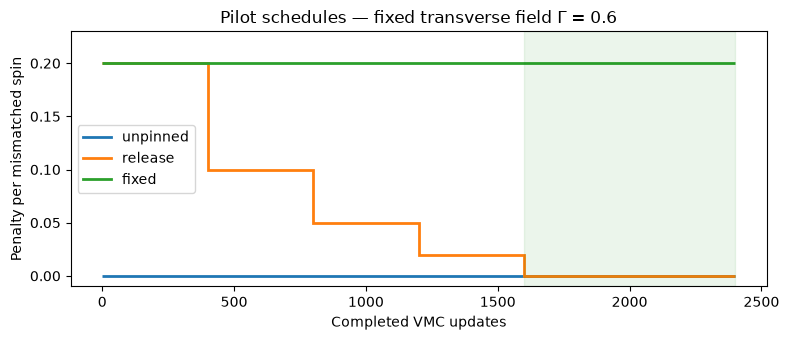

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for arm, stages in schedules.items():
    edges = [0]
    for updates, epsilon in stages:
        edges.append(edges[-1] + updates)
    ax.stairs([epsilon for updates, epsilon in stages], edges, label=arm,
              baseline=None, linewidth=2)
ax.axvspan(1600, 2400, color="green", alpha=0.08)
ax.set(xlabel="Completed VMC updates", ylabel="Penalty per mismatched spin",
        title="Pilot schedules — fixed transverse field Γ = 0.6", ylim=(-0.01, 0.23))
ax.legend()
fig.tight_layout()
plt.show()


## Frozen-guide diagnostics and target-Hamiltonian projection

Adaptive VMC traces describe optimization. Evaluate frozen checkpoints with
fresh RNG streams, independent of training and reference search.

At updates 400, 1600, 2000 and 2400, for every branch, run fixed-parameter tempered
sampling from uniform, reference-aligned and inverse-reference starts. For
the baseline, use all three selected references for the latter two start
families. Use 128 chains/temperature, 400 warmup sweeps and 1024 measurement
sweeps, saving cold states every four sweeps. Record start families separately.
Extend this fixed budget only through an explicit protocol revision if mixing
remains unresolved. All diagnostic sweeps are outside the optimization budget.

The pilot records target energy per site, target local-energy variance divided
by $N$, reference overlaps for **all** bank references, chain-mean energy
spread, exchange rates, temperature round trips and unique configurations.
The analysis reconstructs conditional energy errors, selected energy
autocorrelations, and nearest-reference region masses from saved raw spins
and energies. These regions use reference-index tie breaking and are
descriptive, with no thermodynamic basin interpretation. Training traces
also record the pinned energy. Compare
starts and seeds. Good energy or round trips alone do not establish mixing.
The sampled local-energy variance estimates the quantum variance only when
the Born distribution is sampled correctly; its finite-chain estimate is not
a certified bound.

At final update 2400, freeze each guide and screen **every branch under $H_0$**:
four independent populations of 512 walkers, equilibration time 16, forward
time 16, eight cycles and two independent repeats, matching the existing L6
screen. Use fresh populations and measurement streams; save their starts.
No auxiliary term, adaptation or likelihood-feedback stage enters this screen.
Any optional projection with nonzero pinning is a separately labeled study.

Reconstruct pure diagonal statistics using the validated forward-walking
estimator. Pair independently generated replicas/populations to form

$$
q=\frac1N\sum_i s_i^{(a)}s_i^{(b)},\quad P(q),\quad \langle q^2\rangle,
\qquad C_{ij}=\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle.
$$

Do not substitute the guide's Born samples or the mixed GFMC distribution for
the target ground-state distribution. Preserve per-cycle raw tags, descendant
counts, spins, weights, mixed/growth energies and estimator normalization.
Use the existing connected-spectrum definition and record its normalization.
The exact overlap grid is $q_k=-1+2k/N$ with $k=0,\ldots,N$; compare probability
masses on this shared grid without smoothing.

Screening alarms and repeat discrepancies retain the existing conventions:

| Diagnostic | Proposed screening threshold |
|---|---|
| Descendant genealogy | alarm if ESS < 8 or largest lineage > 0.5 in any island/cycle |
| Energy per site, repeat absolute difference | 0.001 |
| $\langle q^2\rangle$, repeat absolute difference | 0.01 |
| $P(q)$ total variation, $\frac12\sum_k\lvert p_k-p'_k\rvert$ | 0.05 |
| Connected-spectrum mode differences | $\lvert c_k-c'_k\rvert/\max(\lvert c_k\rvert,\lvert c'_k\rvert,0.001)\le0.10$ |

Apply observable comparisons also across references and seeds within each
disorder, reporting all discrepancies rather than only pass counts. These are
diagnostic thresholds, not confidence intervals. Two repeats cannot establish
systematic accuracy. Genealogical ESS is distinct from VMC autocorrelation ESS.

Evidence for a useful intervention would be lower **target** energy fluctuations
after release, better genealogy under $H_0$, and reproducible correlations and
$P(q)$ across references, seeds and repeats. Improvement only while pinned,
or stable energy with reference-dependent overlaps, does not meet that goal.
Even a successful screen requires population-size, projection-time, start and
training-saturation checks before a ground-state claim. Predefine any follow-up
escalation equally across compared arms; this draft does not schedule it.


## Provenance and implementation boundary

Save the design version, full configuration and source hashes; graph and bond
arrays; classical search trajectories and candidate bank; selected reference
bitstrings and selection decisions; initialization checkpoint; model, Adam,
sampler and RNG checkpoint states; every training stage and elapsed time;
frozen diagnostics; raw projection data; all failures, alarms and exclusions.
The implemented RNG namespaces are: NumPy `SeedSequence` for search;
CUDA generator seed `20261104 + seed` for identical initial sampling and
training streams across branches; `300000 + 100*update + start_index` for
frozen sampling, also shared across branches; and hashed task identities
including the branch for independent projection streams. Complete training
RNG states are checkpointed. Preserve all completed
branches and stop failed branches with a recorded reason; no automatic retry
loop, reference substitution or schedule tuning based on favorable results.

The pilot implements an explicit auxiliary-field schedule path using
`sampled_simple_guides.local_energy`, `energy_loss`, `TwoCopyTempering` and
`simple_guides.RBM`. The existing trainer's `steps` is per transverse-field
stage and its field schedule is implicit; it cannot represent this budget by
merely changing one argument. The launched source snapshot remains immutable.

Before any scientific launch, validate the diagonal penalty, $\epsilon=0$
recovery and covariance gradient against exact small-system calculations on
AutoDL; verify resumed versus uninterrupted optimizer/sampler continuation;
audit the target measurement Hamiltonian. The checks executed below validate
only the design arithmetic and notebook, not a trainer implementation.

## Finite pilot choices and possible follow-up

The pilot fixes $\epsilon_0=0.20$, three references, and 2400 updates per
branch, including 800 at zero pinning for each release branch. It uses the
128-start search, 2.16 energy window, and distance-11 diversity rule above.
The bank contains 226 unique candidates; the selected energies are
$-107.4408686$, $-107.2924054$, and $-107.1338829$, with mutual Hamming
distances 38, 29, and 67. These are low-energy candidates from a finite search.
Weaker pinning, more refinement, and additional seeds/disorders are possible
follow-ups requiring a separate finite experimental design.

**The finite pilot is authorized. See the companion results
notebook for measured guide quality and projection diagnostics. Quantum-gap
changes and ground-state convergence remain unestablished.**
